## 1 Sampling intervalls

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

path = "../data/processed/dublin_bikes_all.csv"
df = pd.read_csv(path)

df["last_reported"] = pd.to_datetime(df["last_reported"], errors="coerce")

df = df.sort_values(["station_id", "last_reported"])

# gap in seconds between consecutive reports for the same station
df["gap"] = df.groupby("station_id")["last_reported"].diff()
df["gap_mn"] = df["gap"].dt.total_seconds() / 60 # in minutes (mn)
print(df["gap_mn"].describe())


plt.figure(figsize=(8,4))

df["gap_mn"].dropna().clip(upper=60).hist(bins=30)

plt.xlabel("Sampling interval (minutes)")
plt.ylabel("Frequency")
plt.title("Distribution of Sampling Intervals")

plt.show()


FileNotFoundError: [Errno 2] No such file or directory: '../../data/processed/dublin_bikes_all.csv'

In [ ]:
# Rolling mean per station

# Feature
df["utilisation"] = df["num_bikes_available"] / df["capacity"]

# Sort + set time index (required for time-based rolling)
df = df.sort_values(["station_id", "last_reported"]).set_index("last_reported")

# Time-based rolling mean per station (drop station_id level to align)
rolling = (
    df.groupby("station_id")["utilisation"]
      .rolling("30min", min_periods=1)
)
df["roll_mean_30min"] = rolling.mean().reset_index(level=0, drop=True)
df["roll_std_30min"]  = rolling.std().reset_index(level=0, drop=True)

'''df["roll_mean_30min"] = (
    df.groupby("station_id")["utilisation"]
      .rolling("30min", min_periods=1)
      .mean()
      .reset_index(level=0, drop=True)   # <-- critical line
)'''

# Restore last_reported as a column
df = df.reset_index()

## 3- Weekly view for one station

count                         1205
mean     0 days 00:08:21.659751037
std      0 days 00:21:41.639867985
min                0 days 00:05:00
25%                0 days 00:05:00
50%                0 days 00:05:00
75%                0 days 00:10:00
max                0 days 09:30:00
Name: last_reported, dtype: object
CLARENDON ROW


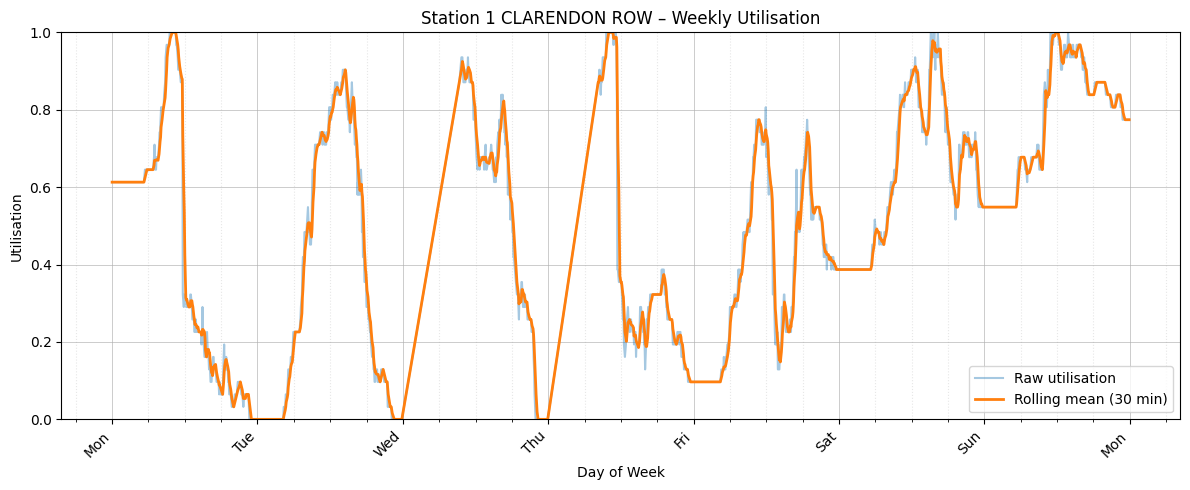

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import matplotlib.ticker as ticker




start = pd.Timestamp("2024-06-03")
end   = pd.Timestamp("2024-06-10")

station_id = 1

station_df = df[
    (df["station_id"] == station_id) &
    (df["last_reported"] >= start) &
    (df["last_reported"] < end)
].sort_values("last_reported")

# # Checks on data missing / mismatch...
## this is on the original df, for all years for this specific station, to check if the sampling interval is consistent
print(station_df["last_reported"].diff().describe())


station_name = station_df["name"].iloc[0]
print(station_name)
week = station_df[(station_df["last_reported"] >= start) & (station_df["last_reported"] < end)]

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(week["last_reported"], week["utilisation"], alpha=0.4, label="Raw utilisation")
ax.plot(week["last_reported"], week["roll_mean_30min"], linewidth=2, label="Rolling mean (30 min)")

# Fix y-axis
ax.set_ylim(0, 1.0)

# Major ticks: one per day (at midnight)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a"))  # Mon Tue Wed...

# Minor ticks = every 6 hours
ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[0,6,12,18]))

# Grid
ax.grid(True, which="major", linewidth=0.5, alpha=0.9)
ax.grid(True, which="minor", linestyle=":", alpha=0.3)

# Rotate only the major tick labels
for label in ax.get_xticklabels(which="major"):
    label.set_rotation(45)
    label.set_ha("right")

ax.set_title(f"Station {station_id} {station_name} – Weekly Utilisation")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Utilisation")
ax.legend()

# Grid: only on major ticks to avoid vertical stripe overload
# ax.grid(True, which="major", alpha=0.3)

plt.tight_layout()
plt.show()

## 4- New DataFrame Creation

In [ ]:
# Dock ratio: ratio of docks available to capacity
df["dock_ratio"] = df["num_docks_available"] / df["capacity"]

# Hour slot: 0-23, where 0 is midnight and 23 is 11 PM
df["hour_slot"] = df["last_reported"].dt.floor("h")

# Days of week: 0-6, where 0 is Monday and 6 is Sunday
df["days_of_week"] = df["last_reported"].dt.dayofweek
df["is_weekend"] = df["days_of_week"] >= 5
df["is_weekday"] = df["days_of_week"] < 5

# Risk: less than 5% of bikes available
df["risk"] = df["utilisation"] < 0.05       

# Antirisk: more than 95% of bikes available
df["antirisk"] = df["utilisation"] > 0.95 

# Features
feature_cols = ["station_id", "hour_slot", "is_weekend", "is_weekday", "roll_mean_30min", "roll_std_30min", "utilisation", "dock_ratio", "risk", "antirisk"]


# Create new DataFrame with features
df_features = df[feature_cols].copy()

print(df_features.head(20))
df_features.describe()

    station_id           hour_slot  is_weekend  is_weekday  roll_mean_30min  \
0            1 2022-04-27 13:00:00       False        True              0.0   
1            1 2022-04-27 13:00:00       False        True              0.0   
2            1 2022-04-27 14:00:00       False        True              0.0   
3            1 2022-04-27 14:00:00       False        True              0.0   
4            1 2022-04-27 15:00:00       False        True              0.0   
5            1 2022-04-27 15:00:00       False        True              0.0   
6            1 2022-04-27 16:00:00       False        True              0.0   
7            1 2022-04-27 16:00:00       False        True              0.0   
8            1 2022-04-27 17:00:00       False        True              0.0   
9            1 2022-04-27 17:00:00       False        True              0.0   
10           1 2022-04-27 18:00:00       False        True              0.0   
11           1 2022-04-27 18:00:00       False      

,station_id,hour_slot,roll_mean_30min,roll_std_30min,utilisation,dock_ratio
count,1.351676e+07,13516758,1.351676e+07,1.040721e+07,1.351676e+07,1.351676e+07
mean,5.839655e+01,2024-05-29 08:26:04.568248832,3.801650e-01,1.982916e-02,3.802120e-01,6.110880e-01
min,1.000000e+00,2022-01-01 00:00:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.900000e+01,2023-09-19 14:00:00,1.034483e-01,0.000000e+00,1.000000e-01,3.750000e-01
50%,5.800000e+01,2024-09-02 07:00:00,3.250000e-01,1.397542e-02,3.250000e-01,6.666667e-01
75%,8.800000e+01,2025-03-18 06:00:00,6.000000e-01,2.788867e-02,6.000000e-01,8.947368e-01
max,5.070000e+02,2025-08-31 23:00:00,1.000000e+00,7.071068e-01,1.000000e+00,1.050000e+00
std,3.458595e+01,NaN,3.027811e-01,3.130039e-02,3.041146e-01,3.070822e-01


# 5- Proximity feature

In [ ]:
![Capture d’écran 2026-03-06 173310.png](...)


In [ ]:
!pip install osmnx

   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 2.1/2.1 MB 21.4 MB/s  0:00:00
   ---------------------------------------- 0.0/23.6 MB ? eta -:--:--
   ---------- ----------------------------- 6.0/23.6 MB 29.7 MB/s eta 0:00:01
   ------------------- -------------------- 11.3/23.6 MB 28.8 MB/s eta 0:00:01
   ---------------------------- ----------- 17.0/23.6 MB 28.2 MB/s eta 0:00:01
   ---------------------------------------  23.3/23.6 MB 27.3 MB/s eta 0:00:01
   ---------------------------------------- 23.6/23.6 MB 26.4 MB/s  0:00:00
   ---------------------------------------- 0.0/6.4 MB ? eta -:--:--
   ----------------------------------- ---- 5.8/6.4 MB 27.3 MB/s eta 0:00:01
   ---------------------------------------- 6.4/6.4 MB 25.8 MB/s  0:00:00
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 1.8/1.8 MB 24.1 MB/s  0:00:00

   -----------------------------

In [ ]:
import numpy as np

stations = df[["station_id","lat","lon"]].drop_duplicates()

# Considered as Dublin city center : O Connell Bridge
center_lat = 53.3498
center_lon = -6.2603

# Distance to the center
stations["distance_center"] = np.sqrt((stations["lat"] - center_lat)**2 +(stations["lon"] - center_lon)**2)

# Classification
def center_category(d):
    # Below 1km
    if d < 0.01:
        return 1
    
    # Betwteen 1km and 2km
    elif d < 0.02:
        return 2
    
    # Over 2km 
    else:
        return 3

stations["center_index"] = stations["distance_center"].apply(center_category)

print(stations[["station_id","center_index"]].head())

In [ ]:
import osmnx as ox

def getArea(lat, lon):

  tags = {"landuse": True, "tourism": True}
  gdf = ox.features_from_point((lat, lon), tags=tags, dist=150)

  # Default area
  area = "residential"
  tourism = False

  # Check that the column "landuse" exists and contains at least one valid value
  if "landuse" in gdf.columns and gdf["landuse"].notna().any():
      # Keep the most relevant area
      land = gdf["landuse"].value_counts().idxmax()

      if land in ["commercial", "industrial", "education"]:
          area = "work"
      elif land == "retail":
          area = "retail"

  if "tourism" in gdf.columns and gdf["tourism"].notna().any() or land == "park":
      tourism = True

  print([area, tourism])
  return [area, tourism]

In [ ]:
stations["area_type"] = stations.apply(lambda row: getArea(row["lat"], row["lon"]),
    axis=1
)